In [3]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pickle
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# result

In [ ]:
#bs
from pathlib import Path
from f_NVP import (
    load_crealnvp_checkpoint,
    price_current_options,
    sample_crealnvp,
)
gen_model = "nvp"
validation_chunk_idxs = [15, 24, 78]
batch_size = 16384
target_parameterization = "mt" # mt, ut
validate_samples = False
valid_resample = False
mt_corr = False
lr          = 1e-5 # 논문 : [1e-5, 1e-5, 1e-6, 1e-6, 1e-6]
lr2         = 1e-6
bn_eta      = 256

multiple = 50  # 0: tail filter off, e.g. 5: reject S_T >= 5 * S0 and refill
model_type = "bs"
l1          = 2
l2          = 3
hidden_dim = 100
num_chunks = 485
scale_clip = 5.0

#save_path = f"result/nvp/{model_type}/{gen_model}_{model_type}_{hidden_dim}_{batch_size}_{lr}_{scale_clip}_{validation_chunk_idxs}_chunk{num_chunks}.pt"
save_path = f"result/nvp/{model_type}/{gen_model}_{model_type}_{hidden_dim}_{batch_size}_{l1}-{lr}_{l2}-{lr2}_{scale_clip}_{validation_chunk_idxs}_chunk{num_chunks}.pt"

#save_path = f"result/nvp/{model_type}/{gen_model}_{model_type}_{batch_size}_{l1}-{lr}_{l2}-{lr2}_{scale_clip}_{validation_chunk_idxs}_chunk{num_chunks}.pt"


nvp, nvp_ckpt = load_crealnvp_checkpoint(
    save_path,
    device="cuda",
)

nvp_result_base_path = str(Path(save_path).with_suffix(""))

In [9]:
#hes
from pathlib import Path
from f_NVP import (
    load_crealnvp_checkpoint,
    price_current_options,
    sample_crealnvp,
)
gen_model = "nvp"
validation_chunk_idxs = [15, 24, 78]
batch_size = 16384
target_parameterization = "mt" # mt, ut
validate_samples = False
valid_resample = False
mt_corr = False
lr          = 1e-5 # 논문 : [1e-5, 1e-5, 1e-6, 1e-6, 1e-6]
lr2         = 1e-6
bn_eta      = 256

multiple = 8  # 0: tail filter off, e.g. 5: reject S_T >= 5 * S0 and refill
model_type = "hes"
l1          = 2
l2          = 3
hidden_dim = 100
num_chunks = 485
scale_clip = 5.0

#save_path = f"result/nvp/{model_type}/{gen_model}_{model_type}_{hidden_dim}_{batch_size}_{lr}_{scale_clip}_{validation_chunk_idxs}_chunk{num_chunks}.pt"
#save_path = f"result/nvp/{model_type}/{gen_model}_{model_type}_{hidden_dim}_{batch_size}_{l1}-{lr}_{l2}-{lr2}_{scale_clip}_{validation_chunk_idxs}_chunk{num_chunks}.pt"

save_path = f"result/nvp/{model_type}/{gen_model}_{model_type}_{batch_size}_{l1}-{lr}_{l2}-{lr2}_{scale_clip}_{validation_chunk_idxs}_chunk{num_chunks}.pt"


nvp, nvp_ckpt = load_crealnvp_checkpoint(
    save_path,
    device="cuda",
)

nvp_result_base_path = str(Path(save_path).with_suffix(""))

# loss history

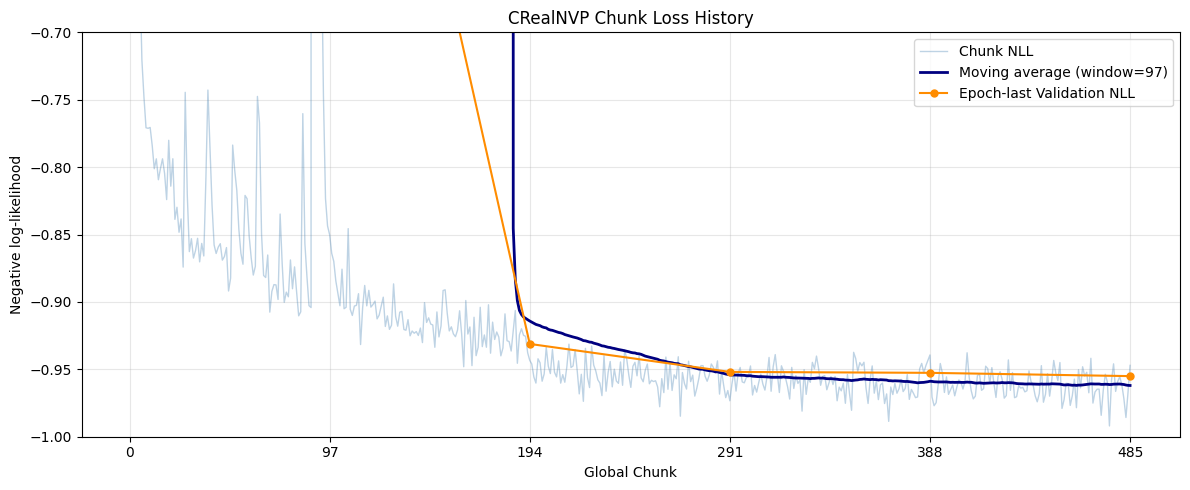

In [11]:
window = 97
epoch = 97
epoch_last_validation_only = True  # False면 모든 validation 기록 표시

chunk_history = nvp_ckpt["chunk_loss_history"]

chunk_nll = np.asarray(chunk_history["nll"], dtype=float,)

global_chunks = np.asarray(
    chunk_history.get(
        "global_chunk",
        np.arange(1, len(chunk_nll) + 1),
    ),
    dtype=int,
)

# 이동평균
moving_average = np.convolve(chunk_nll, np.ones(window) / window, mode="valid",)
moving_average_chunks = global_chunks[window - 1:]

# Chunk 단위 validation history
validation_history = nvp_ckpt.get("validation_history", {})
validation_chunks = np.asarray(validation_history.get("global_chunk", []), dtype=int,)
validation_nll = np.asarray(validation_history.get("nll", []),dtype=float,)
validation_epochs = np.asarray(
    validation_history.get(
        "epoch", ((validation_chunks - 1) // epoch + 1).tolist(),
    ),
    dtype=int,
)
if epoch_last_validation_only and len(validation_nll) > 0:
    if len(validation_epochs) != len(validation_nll):
        raise ValueError("validation epoch과 loss 기록 길이가 다릅니다.")
    last_indices = np.asarray([
        np.flatnonzero(validation_epochs == epoch_value)[-1]
        for epoch_value in np.unique(validation_epochs)
    ], dtype=int)
    plotted_validation_chunks = validation_chunks[last_indices]
    plotted_validation_nll = validation_nll[last_indices]
else:
    plotted_validation_chunks = validation_chunks
    plotted_validation_nll = validation_nll


# Plot
plt.figure(figsize=(12, 5))
plt.plot(
    global_chunks,
    chunk_nll,
    color="steelblue",
    linewidth=1,
    alpha=0.35,
    label="Chunk NLL",
)

# Window 이동평균
plt.plot(
    moving_average_chunks,
    moving_average,
    color="navy",
    linewidth=2,
    label=f"Moving average (window={window})",
)

# Chunk 단위 Validation NLL
if len(plotted_validation_nll) > 0:
    plt.plot(
        plotted_validation_chunks,
        plotted_validation_nll,
        color="darkorange",
        marker="o",
        linewidth=1.5,
        markersize=5,
        label=("Epoch-last Validation NLL" if epoch_last_validation_only else "Validation NLL"),
    )

plt.xlabel("Global Chunk")
plt.ylabel("Negative log-likelihood")
if "bs" in save_path:
    if "ut" in save_path:
        plt.ylim(1.68, 1.74)
    else:
        plt.ylim(-1, -0.7)
else:    
    plt.ylim(-1.55, -1.3)
plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(epoch))
plt.title("CRealNVP Chunk Loss History")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# inference result

In [74]:
timing_option = "barr_put"  # van_call, van_put, barr_call, barr_put
timing_n_samples = 100_000

In [75]:
import time
import torch
from f_NVP import sample_valid_crealnvp

# 가격 계산에 사용할 인자
timing_S0 = 1.0
timing_K = 1.0
timing_B = 0.8
timing_r = 0.03
timing_T = 1.5
timing_repeats = 50

if model_type in ("hes", "hes_clip"):
    # [r, kappa, theta, xi, rho, Y0, T]
    timing_eta_raw = np.asarray(
        [timing_r, 2.0, 0.05, 0.5, -0.7, 0.05, timing_T],
        dtype=np.float32,
    )
else:
    # [r, sigma, T]
    timing_eta_raw = np.asarray(
        [timing_r, np.sqrt(0.05), timing_T],
        dtype=np.float32,
    )

timing_option_labels = {
    "van_call": "Vanilla Call",
    "van_put": "Vanilla Put",
    "barr_call": "Barrier Call",
    "barr_put": "Barrier Put",
}
if timing_option not in timing_option_labels:
    raise ValueError(f"지원하지 않는 timing_option: {timing_option}")
timing_device = next(nvp.parameters()).device

def synchronize_timing_device():
    if timing_device.type == "cuda":
        torch.cuda.synchronize(timing_device)

def run_timing_price(seed):
    raw_samples = sample_crealnvp(
        nvp, nvp_ckpt, timing_eta_raw,
        n_samples=timing_n_samples, antithetic=False, seed=seed,
    )
    if validate_samples or multiple > 0:
        samples, _ = sample_valid_crealnvp(
            nvp, nvp_ckpt, timing_eta_raw,
            n_samples=timing_n_samples, antithetic=False, seed=seed,
            valid_resample=valid_resample,
            initial_samples=raw_samples,
            validate_support=validate_samples,
            multiple=multiple,
        )
    else:
        samples = raw_samples

    X_T = samples[:, 0]
    S_T = timing_S0 * torch.exp(X_T)
    if timing_option.startswith("barr_"):
        M_T = samples[:, 1]
        if mt_corr:
            M_T = torch.minimum(M_T, torch.minimum(torch.zeros_like(X_T), X_T))
        alive = (timing_S0 * torch.exp(M_T) > timing_B).to(S_T.dtype)
    else:
        alive = 1.0

    if timing_option.endswith("call"):
        payoff = torch.clamp(S_T - timing_K, min=0.0)
    else:
        payoff = torch.clamp(timing_K - S_T, min=0.0)
    return float(np.exp(-timing_r * timing_T) * (payoff * alive).mean().item())

# CUDA 초기화 등의 일회성 비용은 평균에서 제외
_ = run_timing_price(seed=1233)
synchronize_timing_device()

timing_elapsed = []
timing_prices = []
for repeat_idx in range(timing_repeats):
    synchronize_timing_device()
    started_at = time.perf_counter()
    price = run_timing_price(seed=1234 + repeat_idx)
    synchronize_timing_device()
    timing_elapsed.append(time.perf_counter() - started_at)
    timing_prices.append(price)

print(f"model={model_type}, samples={timing_n_samples:,}, repeats={timing_repeats}")
print(f"eta={timing_eta_raw.tolist()}")
print(f"{timing_option_labels[timing_option]:12s}: {np.mean(timing_prices):.8f}")
print(
    f"average time : {np.mean(timing_elapsed):.5f} s "
    f"({np.mean(timing_elapsed) * 1_000:.3f} ms, {timing_repeats}-run average)"
)

model=hes, samples=100,000, repeats=50
eta=[0.029999999329447746, 2.0, 0.05000000074505806, 0.5, -0.699999988079071, 0.05000000074505806, 1.5]
Barrier Put : 0.00527706
average time : 0.03223 s (32.233 ms, 50-run average)


In [4]:
S0 = 1.0
K = 1.0
B = 0.8
r = 0.03
sigma = np.sqrt(0.05)
T = 1.5

if model_type in ("hes", "hes_clip"):
    test_etas = [0.03, 2.0, 0.05, 0.5, -0.7, 0.05, 1.5]
else:
    test_etas = [0.03, np.sqrt(0.05), 1.5]

eta_raw = np.asarray(test_etas, dtype=np.float32)

option_keys = ["van_call", "van_put", "barr_call", "barr_put"]
n_list = [1_000, 10_000, 100_000]
n_repeats = 50
results_by_option = {key: {n: [] for n in n_list} for key in option_keys}
sampling_diagnostics_by_n = {n: [] for n in n_list}

for n in n_list:
    for repeat_idx in range(n_repeats):
        prices = price_current_options(
            nvp, nvp_ckpt, eta_raw, S0=S0, K=K, B=B, r=r, T=T,
            n_samples=n, antithetic=False, seed=1234 + repeat_idx,
            validate_samples = validate_samples,
            valid_resample = valid_resample,
            mt_corr = mt_corr,
            multiple = multiple,
        )

        sampling_diagnostics_by_n[n].append({
            key: prices.get(key) for key in (
                "used_sample_count", "discarded_sample_count",
                "discarded_sample_pct", "regenerated_sample_count",
                "regenerated_sample_pct", "support_invalid_count",
                "tail_rejected_sample_count", "tail_rejected_sample_pct",
                "multiple", "X_T_upper",
            )
        })

        for key in option_keys:
            results_by_option[key][n].append(prices[key])

for key in option_keys:
    result_path = f"{nvp_result_base_path}_{key}.pkl"

    with open(result_path, "wb") as file:
        pickle.dump(results_by_option[key], file)

    print(f"saved: {result_path}")

diagnostics_path = f"{nvp_result_base_path}_sampling_diagnostics.pkl"
with open(diagnostics_path, "wb") as file:
    pickle.dump(sampling_diagnostics_by_n, file)
print(f"saved: {diagnostics_path}")

saved: result/nvp/bs/nvp_bs_100_16384_2-1e-05_3-1e-06_5.0_[15, 24, 78]_chunk485_van_call.pkl
saved: result/nvp/bs/nvp_bs_100_16384_2-1e-05_3-1e-06_5.0_[15, 24, 78]_chunk485_van_put.pkl
saved: result/nvp/bs/nvp_bs_100_16384_2-1e-05_3-1e-06_5.0_[15, 24, 78]_chunk485_barr_call.pkl
saved: result/nvp/bs/nvp_bs_100_16384_2-1e-05_3-1e-06_5.0_[15, 24, 78]_chunk485_barr_put.pkl
saved: result/nvp/bs/nvp_bs_100_16384_2-1e-05_3-1e-06_5.0_[15, 24, 78]_chunk485_sampling_diagnostics.pkl


Vanilla Call
n=  1000 | mean=0.13061897 | std =0.00809215 |95% CI=±0.01586061 | error=+0.52%
n= 10000 | mean=0.12918634 | std =0.00232300 |95% CI=±0.00455309 | error=-0.58%
n=100000 | mean=0.12858130 | std =0.00060601 |95% CI=±0.00118777 | error=-1.05%

Vanilla Put
n=  1000 | mean=0.08585644 | std =0.00348805 |95% CI=±0.00683658 | error=-0.10%
n= 10000 | mean=0.08577663 | std =0.00106721 |95% CI=±0.00209172 | error=-0.19%
n=100000 | mean=0.08587721 | std =0.00034950 |95% CI=±0.00068502 | error=-0.08%

Barrier Call
n=  1000 | mean=0.12456303 | std =0.00799140 |95% CI=±0.01566314 | error=+0.87%
n= 10000 | mean=0.12319000 | std =0.00228957 |95% CI=±0.00448756 | error=-0.25%
n=100000 | mean=0.12257658 | std =0.00059396 |95% CI=±0.00116416 | error=-0.74%

Barrier Put
n=  1000 | mean=0.01032195 | std =0.00084406 |95% CI=±0.00165436 | error=+8.25%
n= 10000 | mean=0.01035922 | std =0.00035680 |95% CI=±0.00069933 | error=+8.64%
n=100000 | mean=0.01036051 | std =0.00009448 |95% CI=±0.00018518 | 

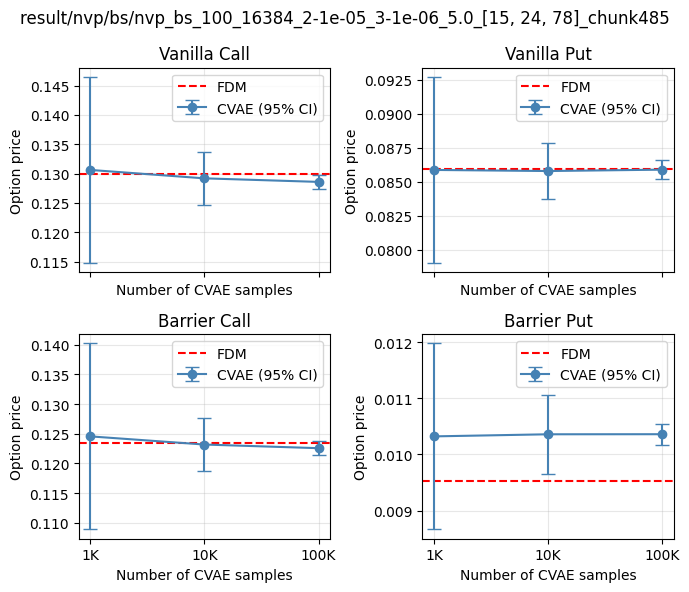

In [5]:
# CVAE inference result graphs for four option payoffs
n_list = [1000, 10000, 100000]
option_keys = ["van_call", "van_put", "barr_call", "barr_put"]
option_labels = {
    "van_call": "Vanilla Call",
    "van_put": "Vanilla Put",
    "barr_call": "Barrier Call",
    "barr_put": "Barrier Put",
}
bench_prices = {
    "hes": {
        "van_call": 0.124491,
        "van_put": 0.080488,
        "barr_call": 0.115733,
        "barr_put": 0.005170,
    },
    "bs": {
        "van_call": 0.129944,
        "van_put": 0.085942,
        "barr_call": 0.123493,
        "barr_put": 0.009535,
    },
    "hes_clip": {
        "van_call": 0.124491,
        "van_put": 0.080488,
        "barr_call": 0.115733,
        "barr_put": 0.005170,
    },
    "bs_clip": {
        "van_call": 0.129944,
        "van_put": 0.085942,
        "barr_call": 0.123493,
        "barr_put": 0.009535,
    },
}
fig, axes = plt.subplots(2, 2, figsize=(7, 6), sharex=True)
axes = axes.ravel()

for ax, key in zip(axes, option_keys):
    with open(f"{nvp_result_base_path}_{key}.pkl", "rb") as f:
        results = pickle.load(f)

    means = np.array([np.mean(results[n]) for n in n_list])
    stds = np.array([np.std(results[n]) for n in n_list])
    ci = 1.96 * stds
    bench = bench_prices[model_type][key]

    print(option_labels[key])
    for n, mean, std, err in zip(n_list, means, stds, ci):
        rel_err = (mean - bench) / (bench) * 100
        print(f"n={n:6d} | mean={mean:.8f} | std ={std:.8f} |95% CI=±{err:.8f} | error={rel_err:+.2f}%")
    print()

    ax.axhline(bench, color="red", linestyle='--', linewidth=1.5, label="FDM")
    ax.errorbar(
        range(len(n_list)), means,
        yerr=ci, fmt="o-", color="steelblue", capsize=5, label="CVAE (95% CI)",
    )
    ax.set_xticks(range(len(n_list)))
    ax.set_xticklabels(["1K", "10K", "100K"])
    ax.set_title(option_labels[key])
    ax.set_xlabel("Number of CVAE samples")
    ax.set_ylabel("Option price")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(nvp_result_base_path)
plt.tight_layout()
plt.show()

# robust

In [10]:
# CVAE robust 셀과 같은 기준으로 NVP 결과만 새로 계산
from pathlib import Path
import pandas as pd
import torch

from f_NVP import price_current_options
from f_robust import (
    ROBUSTNESS_VARIABLES_MAIN,
    run_robustness,
    save_robustness_results,
)

# f_robust의 eta 형식: (S0, K, 모델 파라미터들...)
BS_eta = (1.0, 1.0, 0.03, np.sqrt(0.05), 1.5)
Hes_eta = (1.0, 1.0, 0.03, 2.0, 0.05, 0.5, -0.7, 0.05, 1.5)
robust_barrier = 0.8
n_samples_list = (1_000, 10_000, 100_000)
nvp_repeats = 50

class NVPPriceAdapter:
    # f_robust가 기대하는 total_pricing 인터페이스를 NVP에 연결한다.
    def __init__(self, model, checkpoint, seed=1234, multiple=0):
        self.model = model
        self.checkpoint = checkpoint
        self.seed = seed
        self.call_count = 0
        # f_robust는 생성기가 running minimum을 출력하는지 dim_x로 확인한다.
        self.dim_x = int(checkpoint.get("dim_x", getattr(model, "dim_x", 2)))
        self.multiple = multiple

        eta_min = checkpoint["eta_min"]
        eta_max = checkpoint["eta_max"]
        if torch.is_tensor(eta_min):
            eta_min = eta_min.detach().cpu().numpy()
        if torch.is_tensor(eta_max):
            eta_max = eta_max.detach().cpu().numpy()
        self.eta_min = np.asarray(eta_min, dtype=np.float32)
        self.eta_max = np.asarray(eta_max, dtype=np.float32)

    def total_pricing(
        self, eta_scaled, B, K, r, T, n_samples,
        validate_samples=True, valid_resample=True, mt_corr=False,
        multiple=None,
    ):
        effective_multiple = self.multiple if multiple is None else multiple
        if torch.is_tensor(eta_scaled):
            eta_scaled = eta_scaled.detach().cpu().numpy()
        eta_scaled = np.asarray(eta_scaled, dtype=np.float32)

        # f_robust의 정규화를 정확히 역변환한다.
        eta_raw = eta_scaled * (self.eta_max - self.eta_min + 1e-8) + self.eta_min
        eta_raw = np.asarray(eta_raw, dtype=np.float32)
        eta_raw[0] = float(r)
        eta_raw[-1] = float(T)

        # invalid 재추출에 쓰이는 내부 seed와 다음 반복의 seed가 겹치지 않게 간격을 둔다.
        current_seed = self.seed + 1_000 * self.call_count
        self.call_count += 1
        return price_current_options(
            self.model,
            self.checkpoint,
            eta_raw,
            S0=1.0,
            K=float(K),
            B=float(B),
            r=float(r),
            T=float(T),
            n_samples=int(n_samples),
            antithetic=False,
            seed=current_seed,
            validate_samples=validate_samples,
            valid_resample=valid_resample,
            mt_corr=mt_corr,
            multiple=effective_multiple,
        )


# Closed/FDM/MC 기준값은 CVAE robust 계산 결과를 그대로 재사용한다.
if model_type in ("bs", "bs_clip"):
    sigma_upper = ROBUSTNESS_VARIABLES_MAIN["bs"]["sigma"][1]
    if np.isclose(sigma_upper, 0.8):
        old_robust_path = Path(
            "result/robust/cvae_bs_2_128_4096_None_0.0001_1_"
            "[15, 24, 78]_chunk1261_robustness_compat.pkl"
        )
        robust_suffix = "robustness"
    elif np.isclose(sigma_upper, 0.75):
        old_robust_path = Path(
            "result/robust/cvae_bs_normal_weight_2_1024_16384_None_"
            "11-2e-05_12-2e-06_1_barrier_put_0.45_"
            "[15, 24, 78]_chunk1358_fine_robustness2_compat.pkl"
        )
        robust_suffix = "robustness2"
    elif np.isclose(sigma_upper, 0.7):
            old_robust_path = Path(
                "result/robust/cvae_bs_1_256_11_16384_None_1-2e-05_2-2e-06_1_[15, 24, 78]_chunk194_onlyX_resi_robustness3.pkl"
            )
            robust_suffix = "robustness3"
    else:
        raise ValueError(f"재사용할 BS robust 기준 파일이 없습니다: sigma={sigma_upper}")
else:
    old_robust_path = Path(
        "result/robust/cvae_hes_2_128_4096_None_0.0001_1_"
        "[15, 24, 78]_chunk776_robustness_compat.pkl"
    )
    robust_suffix = "robustness"

if not old_robust_path.is_file():
    raise FileNotFoundError(f"robust 기준 파일을 찾을 수 없습니다: {old_robust_path}")

old_results = pd.read_pickle(old_robust_path).copy()
old_results["model"] = model_type

nvp_adapter = NVPPriceAdapter(nvp, nvp_ckpt, seed=1234, multiple=multiple)
adapter_results = run_robustness(
    BS_eta,
    Hes_eta,
    ROBUSTNESS_VARIABLES_MAIN,
    models=(model_type,),
    barrier=robust_barrier,
    barr_types=("van", "barr"),
    option_types=("call", "put"),
    run_fdm=False,
    run_mc=False,
    n_samples_list=n_samples_list,
    mc_repeats=50,
    mc_dt=0.001,
    cvae=nvp_adapter,
    checkpoint=nvp_ckpt,
    device=next(nvp.parameters()).device,
    cvae_repeats=nvp_repeats,
    validate_samples=validate_samples,
    valid_resample=valid_resample,
    mt_corr=mt_corr,
    multiple=multiple,
)

key_cols = ["model", "variable", "value", "barr_type", "option_type"]
generator_cols = [
    "cvae",
    "cvae_std",
    "cvae_seconds",
    "cvae_results",
    "cvae_seconds_by_n",
    "sampling_diagnostics_by_n",
    "used_sample_count",
    "discarded_sample_pct",
    "regenerated_sample_pct",
    "mt_corrected_sample_pct",
    "tail_rejected_sample_pct",
]

# f_robust 내부의 cvae_* 칸을 NVP 저장 공간으로 사용한다.
# 표시 셀에서는 nvp_* 이름으로 바꿔서 보여준다.
adapter_values = adapter_results[key_cols + generator_cols + ["error"]].rename(
    columns={"error": "nvp_error"}
)
old_attrs = dict(old_results.attrs)
new_results = old_results.drop(
    columns=[
        col for col in old_results.columns
        if col.startswith("cvae") or col in generator_cols
    ],
    errors="ignore",
).merge(adapter_values, on=key_cols, how="left")


def combine_robust_errors(row):
    messages = []
    for value in (row.get("error"), row.get("nvp_error")):
        if pd.notna(value) and str(value).strip():
            messages.append(str(value).replace("cvae=", "nvp="))
    return "; ".join(dict.fromkeys(messages)) or None


new_results["error"] = new_results.apply(combine_robust_errors, axis=1)
new_results = new_results.drop(columns="nvp_error")

# Heston도 재사용한 FDM reference를 기준으로 NVP 오차를 다시 계산한다.
nvp_difference = new_results["cvae"] - new_results["reference"]
new_results["cvae_abs_error"] = nvp_difference.abs()
new_results["cvae_rel_error_pct"] = np.where(
    new_results["reference"].abs() > 1e-12,
    nvp_difference.abs() / new_results["reference"].abs() * 100.0,
    np.nan,
)
new_results.attrs.update(old_attrs)
new_results.attrs.update(adapter_results.attrs)
new_results.attrs["generator"] = "NVP"
new_results.attrs["nvp_repeats"] = nvp_repeats

multiple_suffix = "" if multiple == 0 else f"_multiple{multiple:g}"
robust_stem = f"{Path(save_path).stem}{multiple_suffix}_nvp_{robust_suffix}"
pickle_path, csv_path = save_robustness_results(
    new_results,
    output_dir="result/robust",
    stem=robust_stem,
)

# 저장되는 요약 CSV의 열 이름도 NVP로 표시한다.
saved_summary = pd.read_csv(csv_path)
saved_summary = saved_summary.rename(columns={
    col: col.replace("cvae", "nvp", 1)
    for col in saved_summary.columns
    if col.startswith("cvae")
})
saved_summary.to_csv(csv_path, index=False)

print("raw results:", pickle_path)
print("summary    :", csv_path)

[barrier samples] n=1,000 | validation=False | resample=False | mt_corr=False | used=1,000.0 | validation_rejected=not checked | multiple_rejected=0.1 (0.0100%) | regenerated=0.1 (0.0100%) | mt_corrected=0.0000%
[barrier samples] n=10,000 | validation=False | resample=False | mt_corr=False | used=10,000.0 | validation_rejected=not checked | multiple_rejected=0.7 (0.0066%) | regenerated=0.7 (0.0066%) | mt_corrected=0.0000%
[barrier samples] n=100,000 | validation=False | resample=False | mt_corr=False | used=100,000.0 | validation_rejected=not checked | multiple_rejected=8.1 (0.0081%) | regenerated=8.1 (0.0081%) | mt_corrected=0.0000%
[001] hes | r=0.0025 | van call
[002] hes | r=0.0025 | van put
[003] hes | r=0.0025 | barr call
[004] hes | r=0.0025 | barr put
[barrier samples] n=1,000 | validation=False | resample=False | mt_corr=False | used=1,000.0 | validation_rejected=not checked | multiple_rejected=0.0 (0.0040%) | regenerated=0.0 (0.0040%) | mt_corrected=0.0000%
[barrier samples] 

Loading: result/robust/nvp_bs_100_16384_2-1e-05_3-1e-06_5.0_[15, 24, 78]_256_chunk485_multiple10_nvp_robustness.pkl
NVP 결과가 모두 비어 있습니다. 저장된 계산 오류를 확인하세요.


,model,variable,value,error
0,bs,r,0.0025,nvp=TypeError: NVPPriceAdapter.total_pricing()...
4,bs,r,0.0975,nvp=TypeError: NVPPriceAdapter.total_pricing()...
8,bs,sigma,0.0500,nvp=TypeError: NVPPriceAdapter.total_pricing()...
12,bs,sigma,0.8000,nvp=TypeError: NVPPriceAdapter.total_pricing()...
16,bs,T,0.1500,nvp=TypeError: NVPPriceAdapter.total_pricing()...
20,bs,T,2.8500,nvp=TypeError: NVPPriceAdapter.total_pricing()...



bs | r=0.0025


,barr_type,option_type,n_samples,reference,mc_mean,mc_std,mc_rel_error_pct,nvp_mean,nvp_std,nvp_rel_error_pct
0,van,call,1000,0.110592,0.110482,0.006221,0.099747,NaN,NaN,NaN
1,van,call,10000,0.110592,0.109961,0.001969,0.570767,NaN,NaN,NaN
2,van,call,100000,0.110592,0.110598,0.000610,0.004978,NaN,NaN,NaN
3,van,put,1000,0.106849,0.106748,0.003966,0.095045,NaN,NaN,NaN
4,van,put,10000,0.106849,0.106906,0.001330,0.053024,NaN,NaN,NaN
5,van,put,100000,0.106849,0.106944,0.000426,0.089080,NaN,NaN,NaN
6,barr,call,1000,0.104650,0.104641,0.006436,0.008771,NaN,NaN,NaN
7,barr,call,10000,0.104650,0.104030,0.002011,0.592600,NaN,NaN,NaN
8,barr,call,100000,0.104650,0.104644,0.000559,0.006056,NaN,NaN,NaN
9,barr,put,1000,0.010502,0.010496,0.001085,0.056026,NaN,NaN,NaN


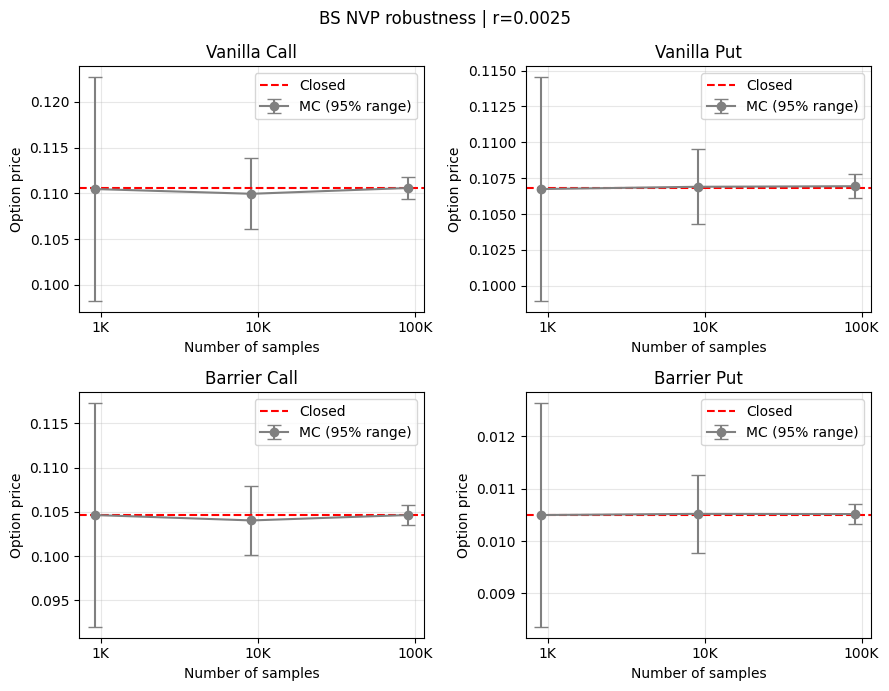


bs | r=0.0975


,barr_type,option_type,n_samples,reference,mc_mean,mc_std,mc_rel_error_pct,nvp_mean,nvp_std,nvp_rel_error_pct
12,van,call,1000,0.183554,0.182742,0.007280,0.442462,NaN,NaN,NaN
13,van,call,10000,0.183554,0.183449,0.002789,0.057266,NaN,NaN,NaN
14,van,call,100000,0.183554,0.183322,0.000837,0.126623,NaN,NaN,NaN
15,van,put,1000,0.047496,0.048155,0.003187,1.387753,NaN,NaN,NaN
16,van,put,10000,0.047496,0.047553,0.000894,0.120251,NaN,NaN,NaN
17,van,put,100000,0.047496,0.047537,0.000289,0.086459,NaN,NaN,NaN
18,barr,call,1000,0.176219,0.175391,0.007091,0.470242,NaN,NaN,NaN
19,barr,call,10000,0.176219,0.176072,0.002735,0.083445,NaN,NaN,NaN
20,barr,call,100000,0.176219,0.175970,0.000862,0.141268,NaN,NaN,NaN
21,barr,put,1000,0.006855,0.006791,0.000946,0.928964,NaN,NaN,NaN


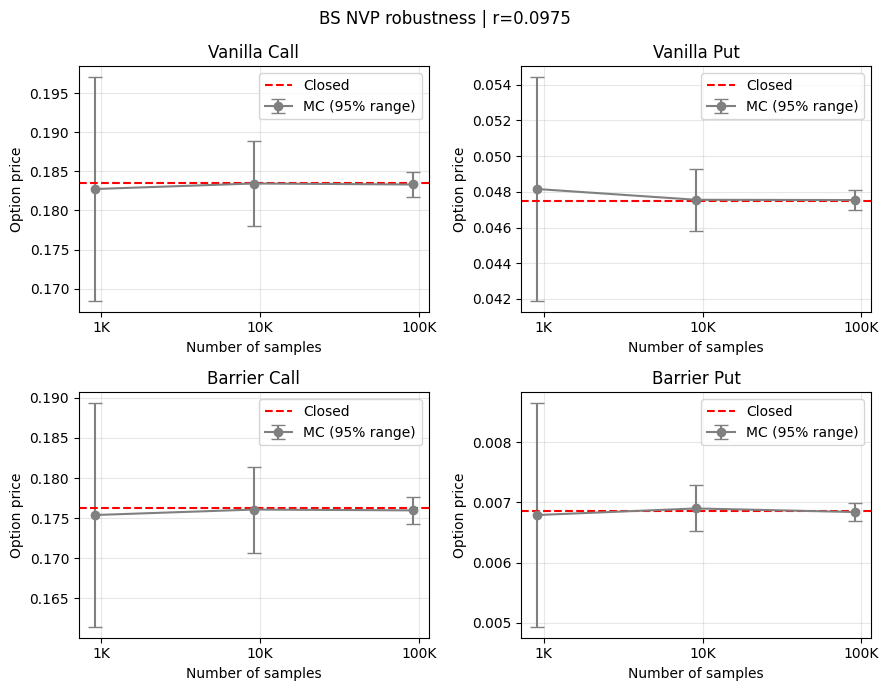


bs | sigma=0.05


,barr_type,option_type,n_samples,reference,mc_mean,mc_std,mc_rel_error_pct,nvp_mean,nvp_std,nvp_rel_error_pct
24,van,call,1000,0.052062,0.052128,0.001701,0.126553,NaN,NaN,NaN
25,van,call,10000,0.052062,0.052021,0.000556,0.078817,NaN,NaN,NaN
26,van,call,100000,0.052062,0.052060,0.000166,0.003739,NaN,NaN,NaN
27,van,put,1000,0.008059,0.008197,0.000622,1.715386,NaN,NaN,NaN
28,van,put,10000,0.008059,0.008102,0.000219,0.528900,NaN,NaN,NaN
29,van,put,100000,0.008059,0.008055,0.000052,0.050163,NaN,NaN,NaN
30,barr,call,1000,0.052062,0.052128,0.001701,0.126553,NaN,NaN,NaN
31,barr,call,10000,0.052062,0.052021,0.000556,0.078817,NaN,NaN,NaN
32,barr,call,100000,0.052062,0.052060,0.000166,0.003739,NaN,NaN,NaN
33,barr,put,1000,0.008056,0.008197,0.000622,1.754534,NaN,NaN,NaN


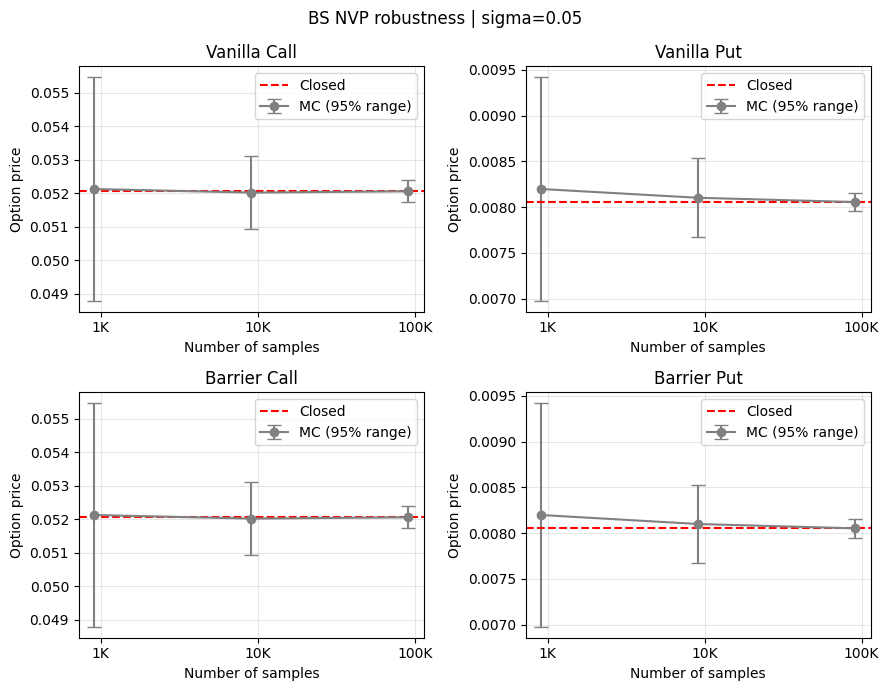


bs | sigma=0.8


,barr_type,option_type,n_samples,reference,mc_mean,mc_std,mc_rel_error_pct,nvp_mean,nvp_std,nvp_rel_error_pct
36,van,call,1000,0.389885,0.389683,0.036722,0.051678,NaN,NaN,NaN
37,van,call,10000,0.389885,0.388580,0.009892,0.334673,NaN,NaN,NaN
38,van,call,100000,0.389885,0.389899,0.003759,0.003706,NaN,NaN,NaN
39,van,put,1000,0.345882,0.345260,0.010896,0.179869,NaN,NaN,NaN
40,van,put,10000,0.345882,0.346917,0.002435,0.299244,NaN,NaN,NaN
41,van,put,100000,0.345882,0.345764,0.000769,0.034250,NaN,NaN,NaN
42,barr,call,1000,0.188650,0.188925,0.029726,0.145638,NaN,NaN,NaN
43,barr,call,10000,0.188650,0.188210,0.007552,0.233149,NaN,NaN,NaN
44,barr,call,100000,0.188650,0.188951,0.003297,0.159876,NaN,NaN,NaN
45,barr,put,1000,0.000292,0.000312,0.000162,6.801918,NaN,NaN,NaN


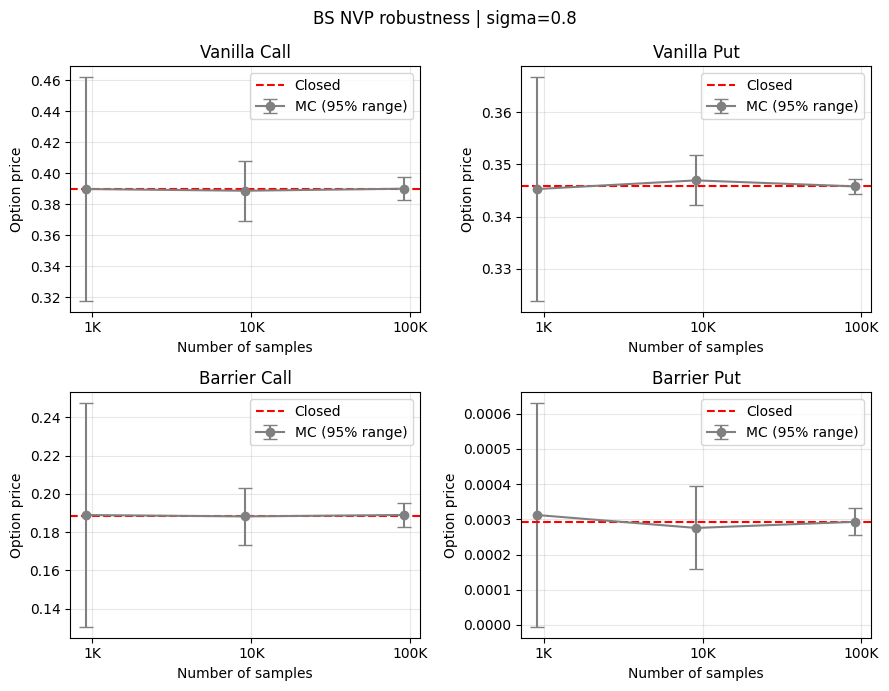


bs | T=0.15


,barr_type,option_type,n_samples,reference,mc_mean,mc_std,mc_rel_error_pct,nvp_mean,nvp_std,nvp_rel_error_pct
48,van,call,1000,0.036753,0.037021,0.001800,0.730612,NaN,NaN,NaN
49,van,call,10000,0.036753,0.036701,0.000518,0.139159,NaN,NaN,NaN
50,van,call,100000,0.036753,0.036762,0.000118,0.026002,NaN,NaN,NaN
51,van,put,1000,0.032263,0.032410,0.001300,0.455806,NaN,NaN,NaN
52,van,put,10000,0.032263,0.032335,0.000436,0.225460,NaN,NaN,NaN
53,van,put,100000,0.032263,0.032267,0.000142,0.014713,NaN,NaN,NaN
54,barr,call,1000,0.036753,0.037021,0.001800,0.730617,NaN,NaN,NaN
55,barr,call,10000,0.036753,0.036701,0.000518,0.139153,NaN,NaN,NaN
56,barr,call,100000,0.036753,0.036762,0.000118,0.025997,NaN,NaN,NaN
57,barr,put,1000,0.030327,0.030435,0.001270,0.358524,NaN,NaN,NaN


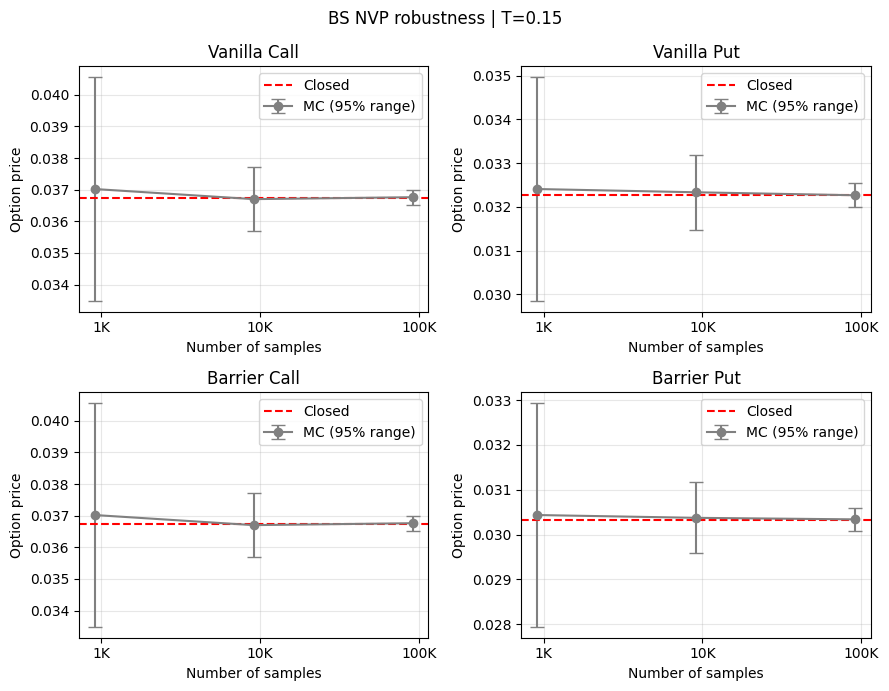


bs | T=2.85


,barr_type,option_type,n_samples,reference,mc_mean,mc_std,mc_rel_error_pct,nvp_mean,nvp_std,nvp_rel_error_pct
60,van,call,1000,0.188168,0.190094,0.009266,1.023408,NaN,NaN,NaN
61,van,call,10000,0.188168,0.188417,0.002867,0.132201,NaN,NaN,NaN
62,van,call,100000,0.188168,0.188247,0.000923,0.042080,NaN,NaN,NaN
63,van,put,1000,0.106221,0.106690,0.004040,0.441411,NaN,NaN,NaN
64,van,put,10000,0.106221,0.106331,0.001399,0.103348,NaN,NaN,NaN
65,van,put,100000,0.106221,0.106161,0.000439,0.057009,NaN,NaN,NaN
66,barr,call,1000,0.163381,0.165080,0.009787,1.040256,NaN,NaN,NaN
67,barr,call,10000,0.163381,0.163458,0.002737,0.047083,NaN,NaN,NaN
68,barr,call,100000,0.163381,0.163417,0.000892,0.022209,NaN,NaN,NaN
69,barr,put,1000,0.004219,0.004140,0.000591,1.860588,NaN,NaN,NaN


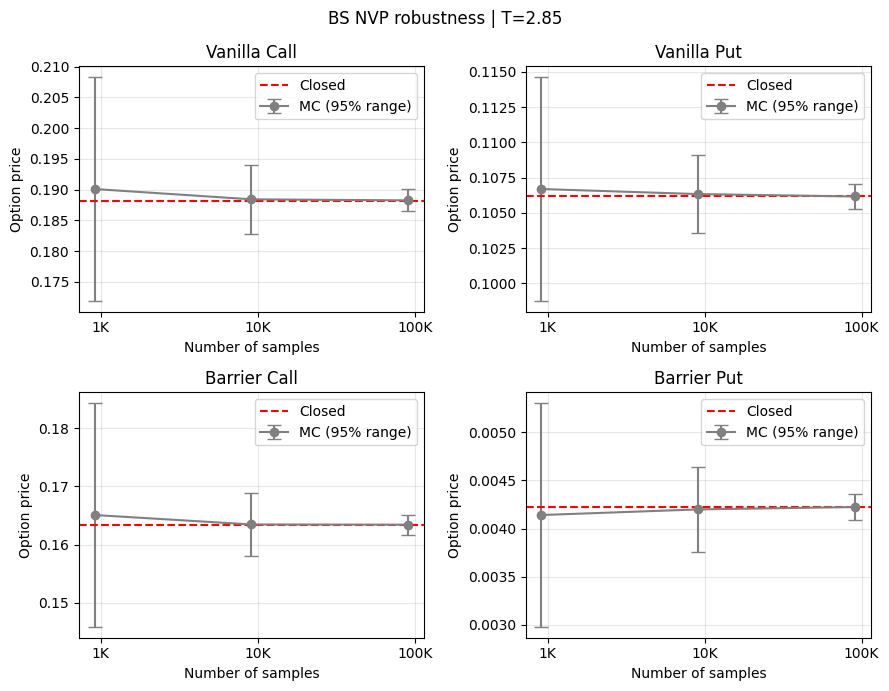


계산 실패 항목


,model,variable,value,barr_type,option_type,error
0,bs,r,0.0025,van,call,nvp=TypeError: NVPPriceAdapter.total_pricing()...
1,bs,r,0.0025,van,put,nvp=TypeError: NVPPriceAdapter.total_pricing()...
2,bs,r,0.0025,barr,call,nvp=TypeError: NVPPriceAdapter.total_pricing()...
3,bs,r,0.0025,barr,put,nvp=TypeError: NVPPriceAdapter.total_pricing()...
4,bs,r,0.0975,van,call,nvp=TypeError: NVPPriceAdapter.total_pricing()...
5,bs,r,0.0975,van,put,nvp=TypeError: NVPPriceAdapter.total_pricing()...
6,bs,r,0.0975,barr,call,nvp=TypeError: NVPPriceAdapter.total_pricing()...
7,bs,r,0.0975,barr,put,nvp=TypeError: NVPPriceAdapter.total_pricing()...
8,bs,sigma,0.0500,van,call,nvp=TypeError: NVPPriceAdapter.total_pricing()...
9,bs,sigma,0.0500,van,put,nvp=TypeError: NVPPriceAdapter.total_pricing()...


In [8]:
# 저장된 NVP robust 결과 확인
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from f_robust import ROBUSTNESS_VARIABLES_MAIN, build_sampling_summary

if model_type in ("bs", "bs_clip") and np.isclose(
    ROBUSTNESS_VARIABLES_MAIN["bs"]["sigma"][1], 0.75
):
    robust_suffix = "robustness2"
else:
    robust_suffix = "robustness"

if multiple == 0:
    robust_stem = f"{Path(save_path).stem}_nvp_{robust_suffix}"
else:
    robust_stem = f"{Path(save_path).stem}_multiple{multiple}_nvp_{robust_suffix}"
pkl_path = Path("result/robust") / f"{robust_stem}.pkl"
print("Loading:", pkl_path)
robust_results = pd.read_pickle(pkl_path)

if robust_results["cvae"].isna().all():
    print("NVP 결과가 모두 비어 있습니다. 저장된 계산 오류를 확인하세요.")
    display(robust_results[["model", "variable", "value", "error"]].drop_duplicates())

if "model" in robust_results.columns and model_type not in set(
    robust_results["model"].astype(str)
) and model_type in {"bs_clip", "hes_clip"}:
    robust_results = robust_results.copy()
    robust_results["model"] = model_type

sampling_summary = build_sampling_summary(robust_results)
option_keys = ("van_call", "van_put", "barr_call", "barr_put")
option_labels = {
    "van_call": "Vanilla Call",
    "van_put": "Vanilla Put",
    "barr_call": "Barrier Call",
    "barr_put": "Barrier Put",
}

for variable, values in ROBUSTNESS_VARIABLES_MAIN[model_type].items():
    for value in values:
        print(f"\n{model_type} | {variable}={value:g}")
        case_summary = sampling_summary[
            sampling_summary["model"].eq(model_type)
            & sampling_summary["variable"].eq(variable)
            & np.isclose(sampling_summary["value"], value)
        ]

        display_table = case_summary[[
            "barr_type",
            "option_type",
            "n_samples",
            "reference",
            "mc_mean",
            "mc_std",
            "mc_rel_error_pct",
            "cvae_mean",
            "cvae_std",
            "cvae_rel_error_pct",
        ]].rename(columns={
            "cvae_mean": "nvp_mean",
            "cvae_std": "nvp_std",
            "cvae_rel_error_pct": "nvp_rel_error_pct",
        })
        display(display_table)

        # plot_sampling_comparison과 같은 구성으로 NVP 라벨을 사용한다.
        fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True)
        axes = axes.ravel()
        x_offset = 0.04

        for ax, option_key in zip(axes, option_keys):
            barr_type, option_type = option_key.split("_", 1)
            option_data = case_summary[
                case_summary["barr_type"].eq(barr_type)
                & case_summary["option_type"].eq(option_type)
            ].sort_values("n_samples")
            n_samples = option_data["n_samples"].to_numpy(dtype=int)
            x_positions = np.arange(len(n_samples))

            if option_data["mc_mean"].notna().any():
                ax.errorbar(
                    x_positions - x_offset,
                    option_data["mc_mean"],
                    yerr=1.96 * option_data["mc_std"],
                    fmt="o-",
                    color="grey",
                    capsize=5,
                    label="MC (95% range)",
                )
            if option_data["cvae_mean"].notna().any():
                ax.errorbar(
                    x_positions + x_offset,
                    option_data["cvae_mean"],
                    yerr=1.96 * option_data["cvae_std"],
                    fmt="o-",
                    color="steelblue",
                    capsize=5,
                    label="NVP (95% range)",
                )

            reference = float(option_data["reference"].iloc[0])
            reference_label = "Closed" if model_type in ("bs", "bs_clip") else "FDM"
            ax.axhline(
                reference,
                color="red",
                linestyle="--",
                linewidth=1.5,
                label=reference_label,
            )
            ax.set_xticks(x_positions)
            ax.set_xticklabels([
                f"{n // 1000}K" if n >= 1000 and n % 1000 == 0 else f"{n:,}"
                for n in n_samples
            ])
            ax.tick_params(axis="x", labelbottom=True)
            ax.set_title(option_labels[option_key])
            ax.set_xlabel("Number of samples")
            ax.set_ylabel("Option price")
            ax.grid(True, alpha=0.3)
            ax.legend()

        fig_name = "BS" if model_type in ("bs", "bs_clip") else "Heston"
        fig.suptitle(f"{fig_name} NVP robustness | {variable}={value:g}")
        plt.tight_layout()
        plt.show()

failed_cases = robust_results[robust_results["error"].notna()]
if not failed_cases.empty:
    print("\n계산 실패 항목")
    display(failed_cases[[
        "model", "variable", "value", "barr_type", "option_type", "error"
    ]])